In [1]:
import os
import io
import copy
import random
from tqdm.auto import tqdm 

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import Normalize
import matplotlib.cm as cm

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset

from torchvision import datasets, transforms, models
from torchvision.models import resnet18, ResNet18_Weights

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cpu


/home/rishabhjp/anaconda3/envs/miniproject/lib/python3.10/site-packages/torch/cuda/__init__.py:129: UserWarning: CUDA initialization: Unexpected error from cudaGetDeviceCount(). Did you run some cuda functions before calling NumCudaDevices() that might have already set an error? Error 804: forward compatibility was attempted on non supported HW (Triggered internally at /opt/conda/conda-bld/pytorch_1729647352509/work/c10/cuda/CUDAFunctions.cpp:108.)
  return torch._C._cuda_getDeviceCount() > 0


In [2]:
cat_class, dog_class = 3, 5

transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.4914, 0.4822, 0.4465],
                         std=[0.247, 0.243, 0.261])
])

test_full = datasets.CIFAR10(root='./cifar-10-batches-py', train=False,
                             download=True, transform=transform)

idx = [i for i, y in enumerate(test_full.targets) if y in [cat_class, dog_class]]
labels = [1 if test_full.targets[i] == cat_class else 0 for i in idx]
subset = Subset(test_full, idx)
subset.targets = labels

class CatDog(Dataset):
    def __init__(self, subset): self.s = subset
    def __len__(self): return len(self.s)
    def __getitem__(self, i): x, _ = self.s[i]; return x, self.s.targets[i]

test_loader = DataLoader(CatDog(subset), batch_size=64, shuffle=False)

Files already downloaded and verified


In [3]:
model = resnet18(weights=ResNet18_Weights.DEFAULT)
num_ftrs = model.fc.in_features
model.fc = nn.Linear(num_ftrs, 2)

for p in model.parameters():
    p.requires_grad = False
for layer in [model.layer3, model.layer4, model.fc]:
    for p in layer.parameters():
        p.requires_grad = True

model = model.to(device)

if os.path.exists("model.pth"):
    model.load_state_dict(torch.load("model.pth", map_location=device))
    model.eval()
    print("Model loaded successfully.\n")
    print("Training Summary of the saved model:")
    print("- Total epochs run: 6")
    print("- Early stopping patience: 4")
    print("- Best epoch: 2")
    print("- Best Validation Accuracy: 0.8115")
    print("- Training Accuracy (at best epoch): 0.9986")
    print("- Validation Loss (at best epoch): 1.5279")
else:
    raise FileNotFoundError("model.pth not found.")

Model loaded successfully.

Training Summary of the saved model:
- Total epochs run: 6
- Early stopping patience: 4
- Best epoch: 2
- Best Validation Accuracy: 0.8115
- Training Accuracy (at best epoch): 0.9986
- Validation Loss (at best epoch): 1.5279


/tmp/ipykernel_52183/3321766767.py:14: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("model.pth", map_location=device))


In [4]:
class Encoder(nn.Module):
    def __init__(self, trained_model):
        super().__init__()
        self.features = nn.Sequential(
            trained_model.conv1,
            trained_model.bn1,
            trained_model.relu,
            trained_model.maxpool,
            trained_model.layer1,
            trained_model.layer2,
            trained_model.layer3
        )

    def forward(self, x):
        with torch.no_grad():
            return self.features(x)


encoder = Encoder(model).to(device)
encoder.eval()


Encoder(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True

In [5]:
class SimpleTanhDecoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.decode = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.ReLU(True),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(True),
            nn.ConvTranspose2d(32, 3, kernel_size=4, stride=2, padding=1),
            nn.Tanh()
        )

    def forward(self, x):
        return self.decode(x)


In [6]:
class SimpleSigmoidDecoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.decode = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1),
            nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.ReLU(True),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.ReLU(True),
            nn.ConvTranspose2d(32, 3, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.decode(x)


In [7]:
class MirrorBasicBlock(nn.Module):
    """Reverse of a ResNet BasicBlock, preserving residual skip."""
    def __init__(self, block):
        super().__init__()
        # Mirror convs
        self.deconv2 = self.mirror_conv(block.conv2)
        self.bn2 = nn.BatchNorm2d(block.conv2.in_channels)
        self.deconv1 = self.mirror_conv(block.conv1)
        self.bn1 = nn.BatchNorm2d(block.conv1.in_channels)
        self.relu = nn.ReLU(inplace=True)

        # Mirror downsample (if present)
        if block.downsample is not None:
            down = block.downsample[0]
            self.upsample = nn.Sequential(
                self.mirror_conv(down),
                nn.BatchNorm2d(down.in_channels)
            )
        else:
            self.upsample = None

    def mirror_conv(self, conv):
        """Create a ConvTranspose2d layer that mirrors a given Conv2d layer."""
        return nn.ConvTranspose2d(
            in_channels=conv.out_channels,
            out_channels=conv.in_channels,
            kernel_size=conv.kernel_size,
            stride=conv.stride,
            padding=conv.padding,
            output_padding=1 if conv.stride[0] > 1 else 0,
            bias=False,
        )

    def forward(self, x):
        identity = x
        out = self.deconv2(x)
        out = self.bn2(out)
        out = self.relu(out)

        out = self.deconv1(out)
        out = self.bn1(out)

        if self.upsample is not None:
            identity = self.upsample(identity)

        out += identity
        out = self.relu(out)
        return out


In [8]:
class MRTanhDecoder(nn.Module):
    def __init__(self):
        super(MRTanhDecoder, self).__init__()

        base = models.resnet18(weights=None)

        def mirror_layer(layer):
            blocks = [MirrorBasicBlock(b) for b in reversed(layer)]
            return nn.Sequential(*blocks)

        self.up3 = mirror_layer(base.layer3)
        self.up2 = mirror_layer(base.layer2)
        self.up1 = mirror_layer(base.layer1)

        # Mirror of initial conv (7x7 stride=2)
        self.final = nn.ConvTranspose2d(
            64, 3, kernel_size=7, stride=2, padding=3, output_padding=1
        )

        # Extra step: bring from 16×16 -> 32×32
        self.upsample_final = nn.Sequential(
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False),
            nn.Conv2d(3, 3, kernel_size=3, stride=1, padding=1),
            nn.Tanh()
        )

    def forward(self, x):
        x = self.up3(x)
        x = self.up2(x)
        x = self.up1(x)
        x = self.final(x)
        x = self.upsample_final(x)
        return x

In [9]:
class MRSigmoidDecoder(nn.Module):
    def __init__(self):
        super(MRSigmoidDecoder, self).__init__()

        base = models.resnet18(weights=None)

        def mirror_layer(layer):
            blocks = [MirrorBasicBlock(b) for b in reversed(layer)]
            return nn.Sequential(*blocks)

        self.up3 = mirror_layer(base.layer3)
        self.up2 = mirror_layer(base.layer2)
        self.up1 = mirror_layer(base.layer1)

        # Mirror of initial conv (7x7 stride=2)
        self.final = nn.ConvTranspose2d(
            64, 3, kernel_size=7, stride=2, padding=3, output_padding=1
        )

        # Extra step: bring from 16×16 -> 32×32
        self.upsample_final = nn.Sequential(
            nn.Upsample(scale_factor=2, mode='bilinear', align_corners=False),
            nn.Conv2d(3, 3, kernel_size=3, stride=1, padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.up3(x)
        x = self.up2(x)
        x = self.up1(x)
        x = self.final(x)
        x = self.upsample_final(x)
        return x

In [12]:
decoder_classes = {
    "SimpleTanh": SimpleTanhDecoder,
    "SimpleSigmoid": SimpleSigmoidDecoder,
    "MRTanh": MRTanhDecoder,
    "MRSigmoid": MRSigmoidDecoder,
}

base_dir = "Decoders"
categories = ["Accuracy", "CE", "Compression", "Task-Aware"]

decoders = {}

for category in categories:
    category_dir = os.path.join(base_dir, category)
    decoders[category] = {}

    for name, DecoderClass in decoder_classes.items():
        for file in os.listdir(category_dir):
            if file.startswith(name) and file.endswith(".pth"):
                path = os.path.join(category_dir, file)
                
                # extract alpha value from filename (if present)
                alpha_str = file[len(name):-4]
                alpha = float(alpha_str) if alpha_str else None

                decoder = DecoderClass().to(device)
                decoder.load_state_dict(torch.load(path, map_location=device))
                decoder.eval()

                decoders[category][name] = {
                    "decoder": decoder,
                    "alpha": alpha
                }
                break

df_best_decoders = pd.read_csv("HyperparameterSweep/decoder_summary_results_full.csv")

/tmp/ipykernel_52183/3416046540.py:27: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  decoder.load_state_dict(torch.load(path, map_location=device))


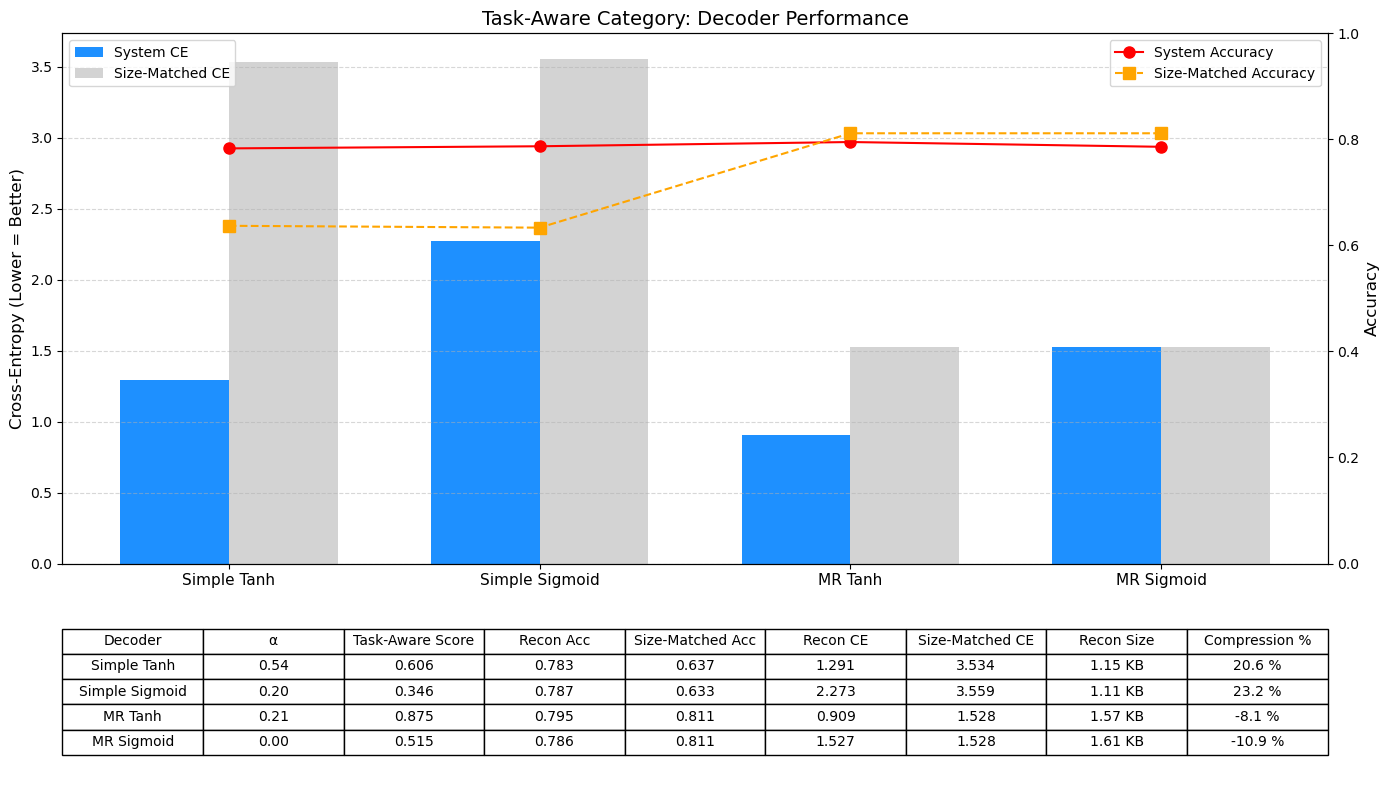

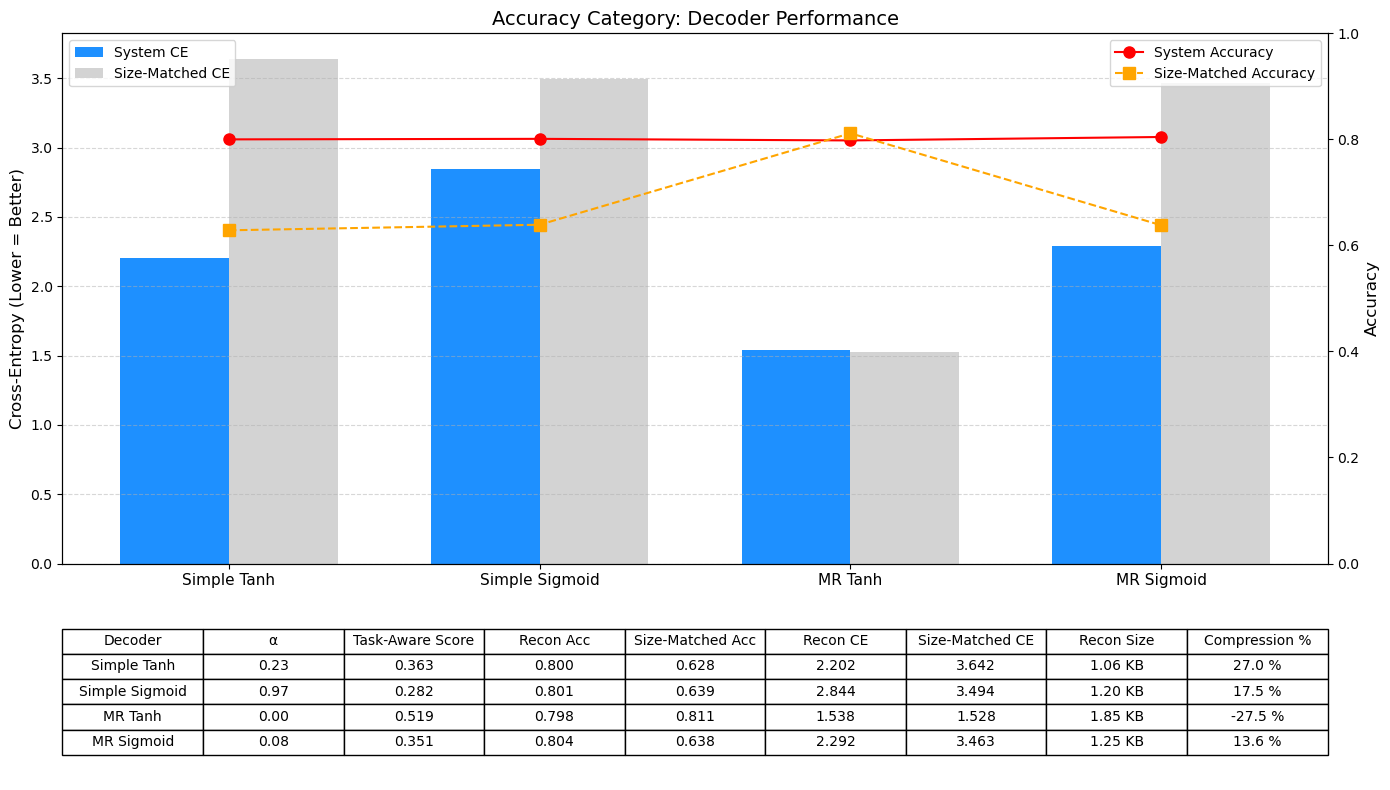

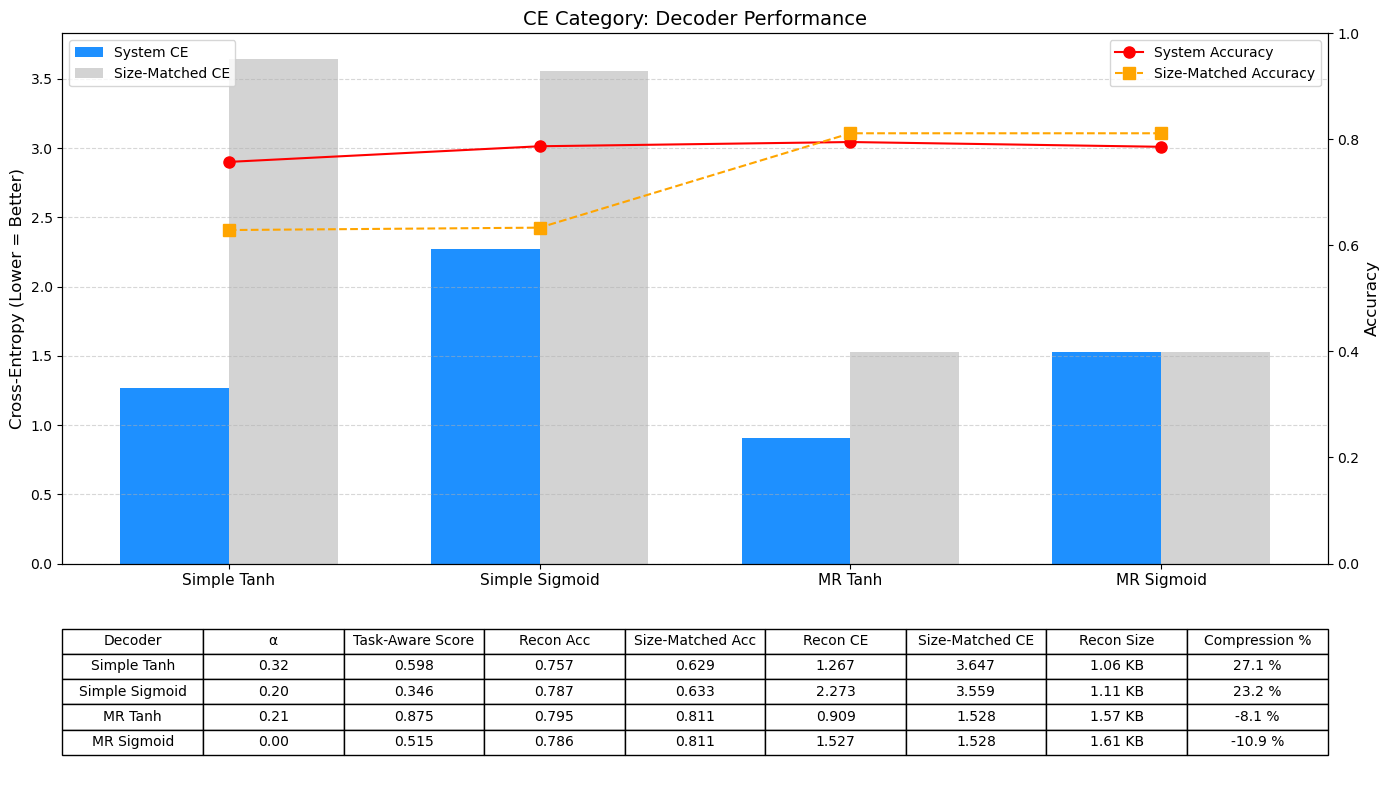

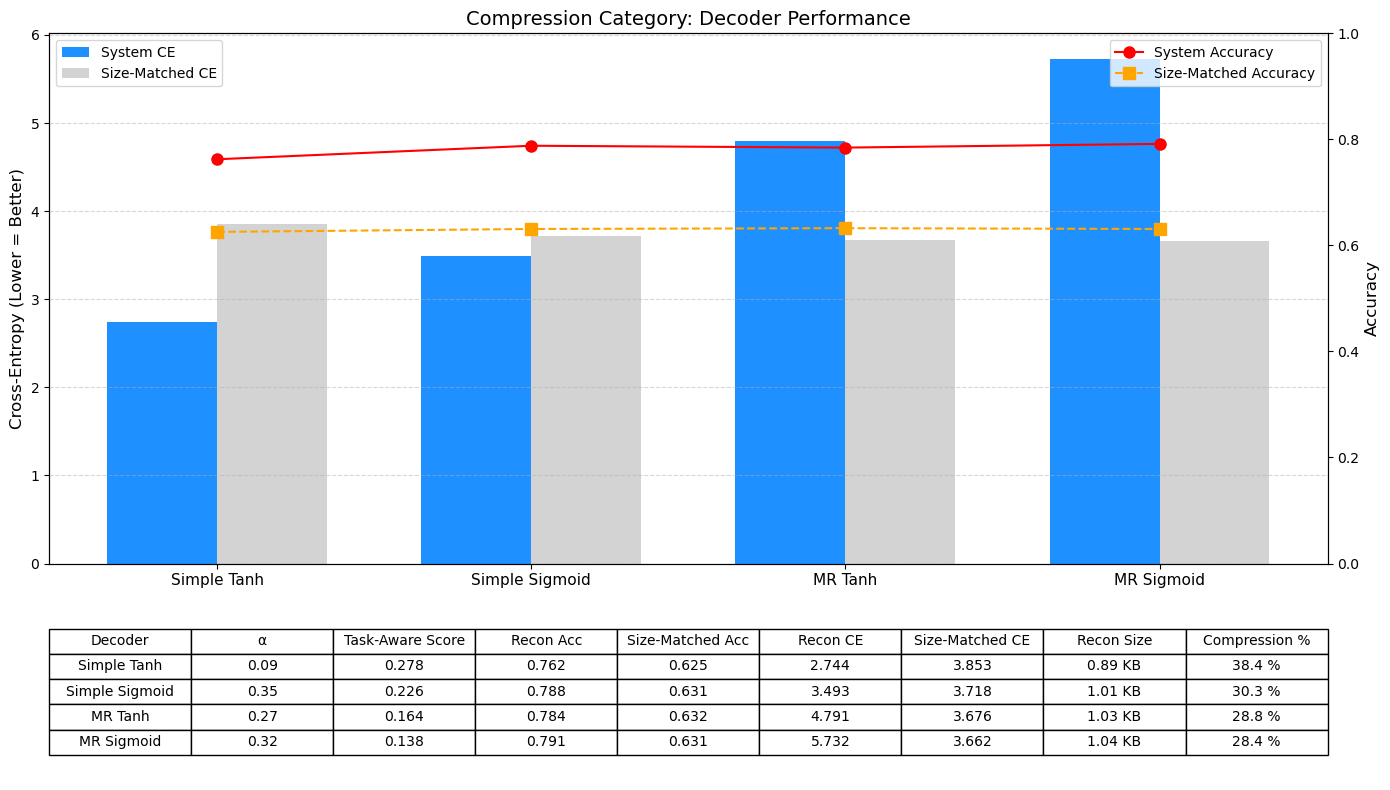

In [13]:
categories = df_best_decoders["Category"].unique()
decoders = df_best_decoders["Decoder"].unique()

for cat in categories:
    # Filter by category
    df_cat = df_best_decoders[df_best_decoders["Category"] == cat].reset_index(drop=True)

    # Extract metrics
    system_CE = df_cat["Recon_CE"].values
    system_acc = df_cat["Recon_Accuracy"].values
    recon_sizes = df_cat["Recon_Size_KB"].values
    compression_pct = df_cat["Compression_%"].values
    alphas = df_cat["Alpha"].values
    taskaware_score = df_cat["Task_Aware_Score"].values
    baseline_acc = df_cat["Baseline_Accuracy"].values
    baseline_CE = df_cat["Baseline_CE"].values

    # Handle negative compression: fallback to baseline
    size_matched_acc = df_cat["Size_Matched_Accuracy"].values.copy()
    size_matched_CE = df_cat["Size_Matched_CE"].values.copy()
    for i, comp in enumerate(compression_pct):
        if comp < 0:  # Expansion instead of compression
            size_matched_acc[i] = baseline_acc[i]
            size_matched_CE[i] = baseline_CE[i]

    x = np.arange(len(decoders))
    width = 0.35

    # Create figure
    fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(14,8), gridspec_kw={'height_ratios':[3,1]})
    ax = axes[0]
    ax_table = axes[1]

    # CE bars
    ax.bar(x - width/2, system_CE, width, color='dodgerblue', label='System CE')
    ax.bar(x + width/2, size_matched_CE, width, color='lightgray', label='Size-Matched CE')

    # X-axis labels
    ax.set_xticks(x)
    ax.set_xticklabels(decoders, fontsize=11)
    ax.set_ylabel("Cross-Entropy (Lower = Better)", fontsize=12)
    ax.set_title(f"{cat} Category: Decoder Performance", fontsize=14)
    ax.grid(axis='y', linestyle='--', alpha=0.5)

    # Accuracy markers
    ax2 = ax.twinx()
    ax2.plot(x, system_acc, 'o-', color='red', label='System Accuracy', markersize=8)
    ax2.plot(x, size_matched_acc, 's--', color='orange', label='Size-Matched Accuracy', markersize=8)
    ax2.set_ylabel("Accuracy", fontsize=12)
    ax2.set_ylim(0,1)

    # Legends
    ax.legend(loc='upper left', fontsize=10)
    ax2.legend(loc='upper right', fontsize=10)

    # Table below
    ax_table.axis('off')
    table_data = []
    for i, decoder in enumerate(decoders):
        table_data.append([
            decoder,
            f"{alphas[i]:.2f}",
            f"{taskaware_score[i]:.3f}",
            f"{system_acc[i]:.3f}",
            f"{size_matched_acc[i]:.3f}",
            f"{system_CE[i]:.3f}",
            f"{size_matched_CE[i]:.3f}",
            f"{recon_sizes[i]:.2f} KB",
            f"{compression_pct[i]:.1f} %"
        ])
    columns = ["Decoder", "α", "Task-Aware Score", "Recon Acc", "Size-Matched Acc", 
               "Recon CE", "Size-Matched CE", "Recon Size", "Compression %"]
    table = ax_table.table(cellText=table_data, colLabels=columns, loc='center', cellLoc='center')
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1,1.2)

    plt.tight_layout()
    plt.show()


In [14]:
decoder_dirs = [
    "HyperparameterSweep/hyperparam_MR_alpha_sigmoid_decoders",
    "HyperparameterSweep/hyperparam_MR_alpha_tanh_decoders",
    "HyperparameterSweep/hyperparam_simple_alpha_sigmoid_decoders",
    "HyperparameterSweep/hyperparam_simple_alpha_tanh_decoders",
]

all_eval_records = []
all_train_records = []

for d in decoder_dirs:
    decoder_name = os.path.basename(d).replace("hyperparam_", "").replace("_decoders","")
    
    # Eval CSV
    eval_csv = os.path.join(d, "decoder_eval_summary.csv")
    if os.path.exists(eval_csv):
        df_eval = pd.read_csv(eval_csv)
        df_eval["decoder_group"] = decoder_name
        all_eval_records.append(df_eval)
    
    # Training CSV
    train_csv = os.path.join(d, "training_summary.csv")
    if os.path.exists(train_csv):
        df_train = pd.read_csv(train_csv)
        df_train["decoder_group"] = decoder_name
        all_train_records.append(df_train)

# Combine all eval and train separately
df_ablation_eval = pd.concat(all_eval_records, ignore_index=True)
df_ablation_train = pd.concat(all_train_records, ignore_index=True)

# Take last epoch per decoder_group + alpha
df_train_last = df_ablation_train.sort_values("epoch").groupby(["decoder_group","alpha"], as_index=False).last()

# Merge evaluation and training on decoder_group + alpha
df_ablation = pd.merge(
    df_ablation_eval,
    df_train_last,
    on=["decoder_group","alpha"],
    how="left"
)
df_ablation["TaskAwareScore"] = df_ablation["recon_acc"] / (df_ablation["recon_CE"] + 1e-6)
print("Merged Ablation DF shape:", df_ablation.shape)
display(df_ablation.head())


Merged Ablation DF shape: (404, 21)


,alpha,baseline_acc,baseline_CE,recon_acc,recon_CE,orig_avg_KB,recon_avg_KB,compression_pct,size_matched_target_KB,size_matched_lossy_acc,...,decoder_group,epoch,raw_CE,raw_MSE,mean_CE,mean_MSE,norm_CE,norm_MSE,L_Total,TaskAwareScore
0,0.00,0.8115,1.527898,0.7860,1.526758,1.450937,1.609404,-10.921758,1.450937,0.6470,...,MR_alpha_sigmoid,63,7.903574e-09,1.242821,0.001686,1.241155,0.000004,1.001492,0.000004,0.514816
1,0.01,0.8115,1.527898,0.7950,1.881289,1.450937,1.361908,6.135955,1.361908,0.6430,...,MR_alpha_sigmoid,13,4.832288e-03,1.178875,0.280385,1.130507,0.015538,1.047765,0.026015,0.422582
2,0.02,0.8115,1.527898,0.7945,2.230324,1.450937,1.377300,5.075116,1.377300,0.6430,...,MR_alpha_sigmoid,74,8.523447e-09,1.142429,0.000576,1.174826,0.000013,0.969453,0.019402,0.356226
3,0.03,0.8115,1.527898,0.7925,1.882873,1.450937,1.463048,-0.834725,1.450937,0.6470,...,MR_alpha_sigmoid,13,2.604629e-03,1.151099,0.275554,1.114258,0.008515,1.036872,0.039621,0.420899
4,0.04,0.8115,1.527898,0.7880,3.021096,1.450937,1.322886,8.825388,1.322886,0.6415,...,MR_alpha_sigmoid,29,2.014876e-04,1.221479,0.058471,1.199253,0.003102,1.020634,0.043928,0.260832


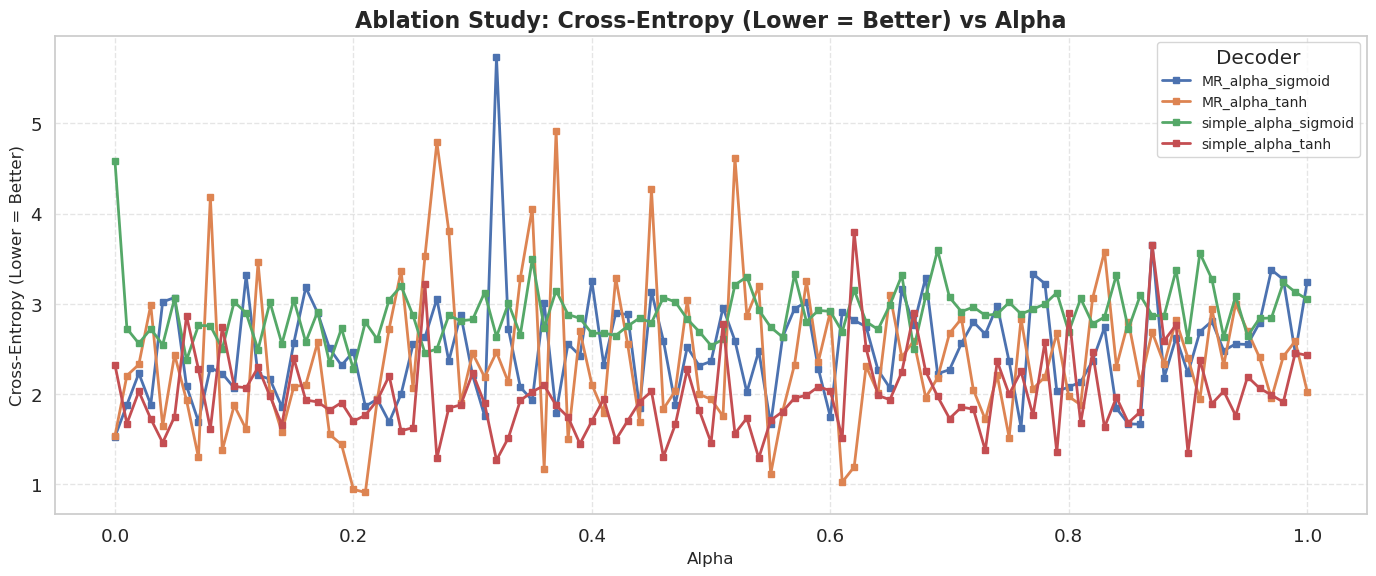

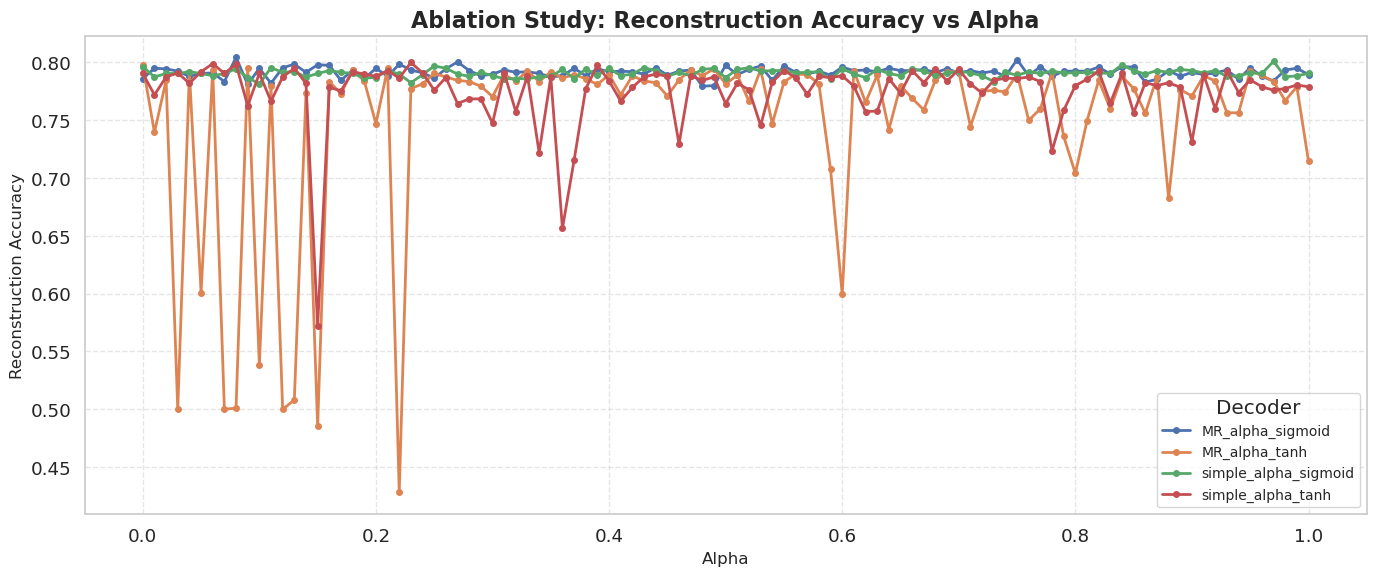

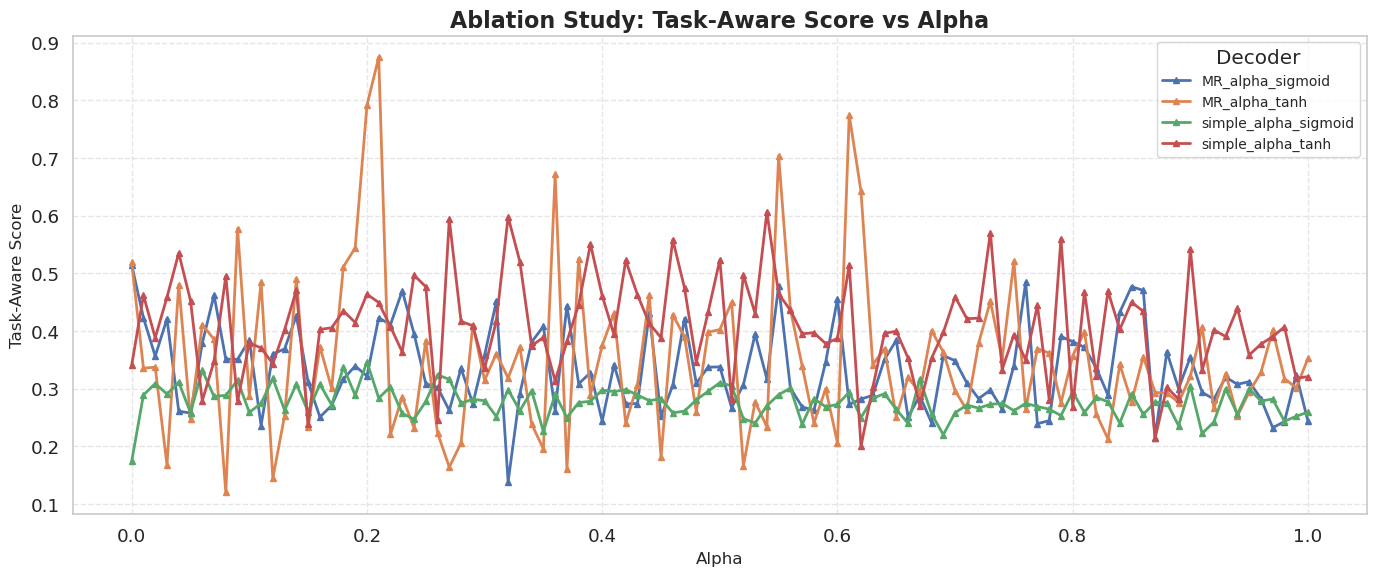

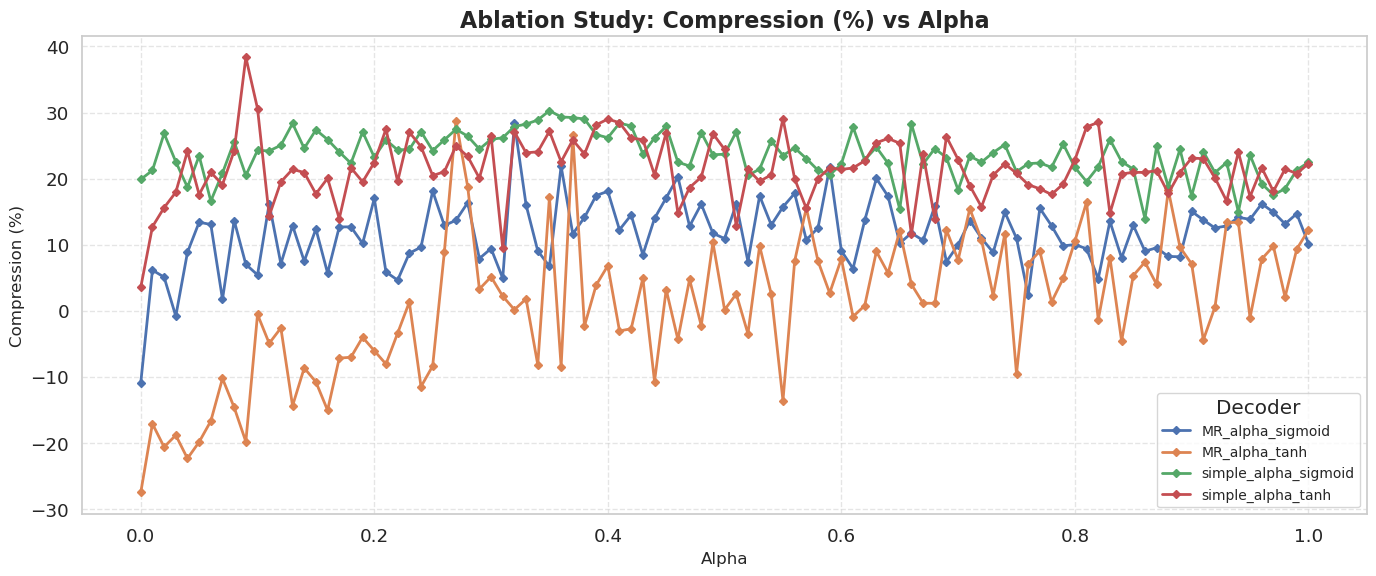

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid", font_scale=1.2)

# Unique decoders
decoders = df_ablation["decoder_group"].unique()

# Metrics and plotting properties
metrics = {
    "recon_CE": {"ylabel": "Cross-Entropy (Lower = Better)", "marker": "s"},
    "recon_acc": {"ylabel": "Reconstruction Accuracy", "marker": "o"},
    "TaskAwareScore": {"ylabel": "Task-Aware Score", "marker": "^"},
    "compression_pct": {"ylabel": "Compression (%)", "marker": "D"}
}

# Plot each metric separately
for metric, props in metrics.items():
    plt.figure(figsize=(14,6))
    plt.title(f"Ablation Study: {props['ylabel']} vs Alpha", fontsize=16, weight='bold')
    
    for decoder in decoders:
        df_dec = df_ablation[df_ablation["decoder_group"] == decoder].sort_values("alpha").reset_index(drop=True)
        plt.plot(df_dec["alpha"], df_dec[metric],
                 label=decoder, marker=props["marker"], linewidth=2, markersize=4)
    
    plt.xlabel("Alpha", fontsize=12)
    plt.ylabel(props["ylabel"], fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend(title="Decoder", fontsize=10, loc='best', frameon=True)
    plt.tight_layout()
    plt.show()


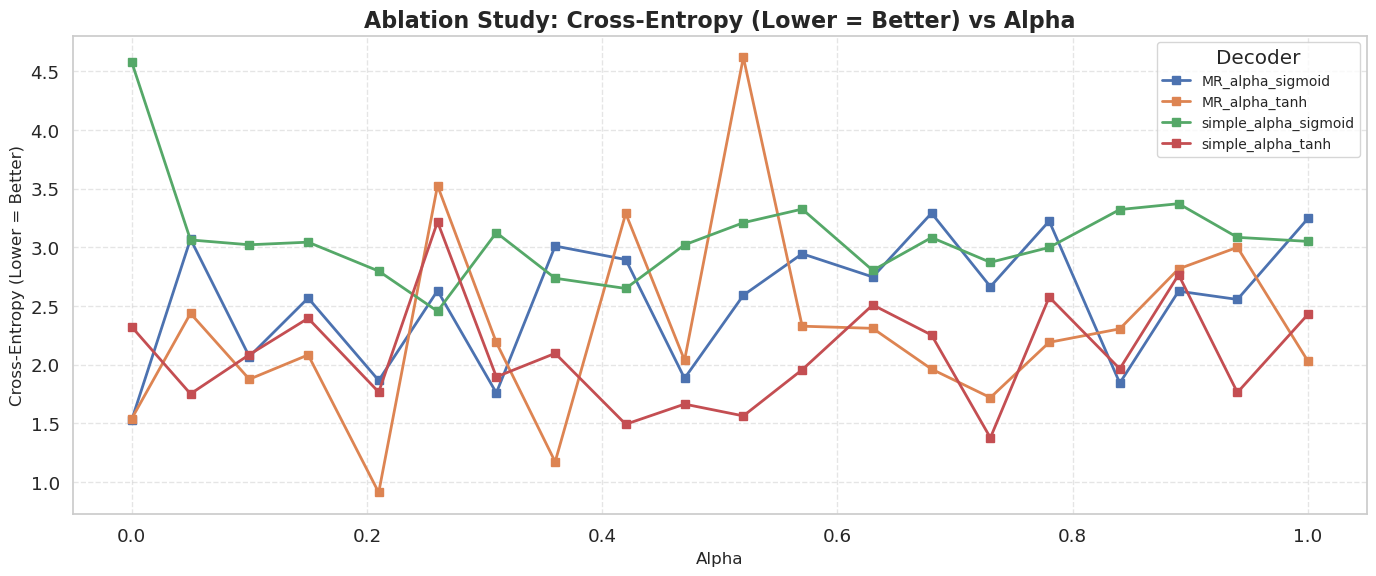

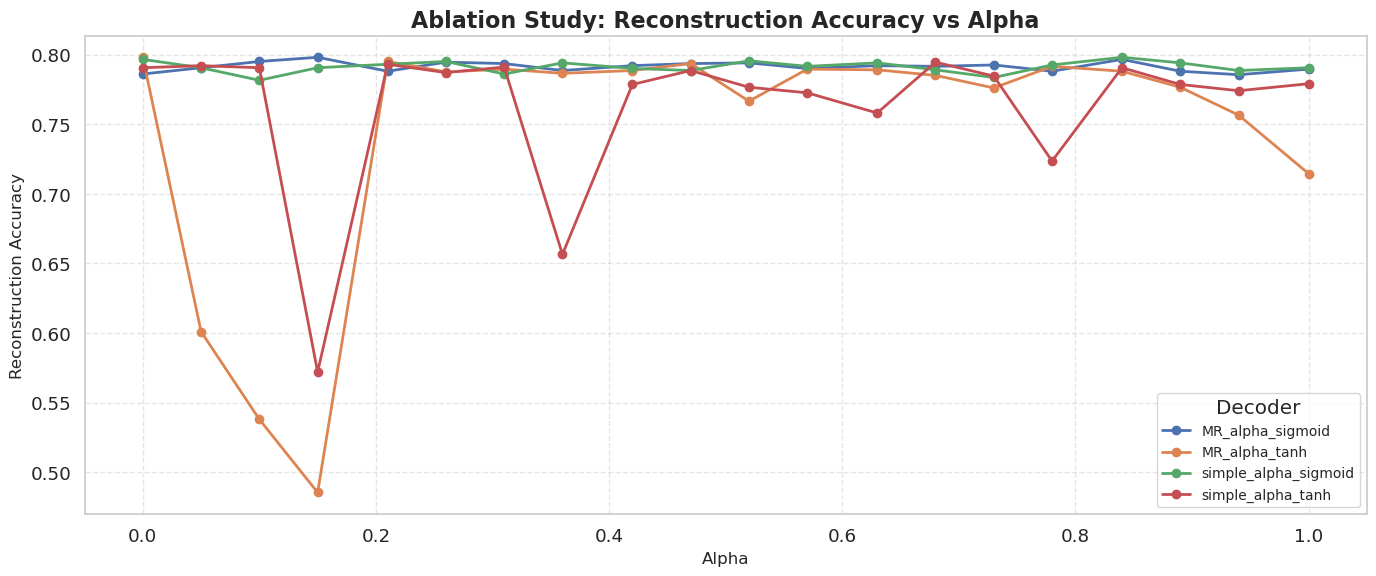

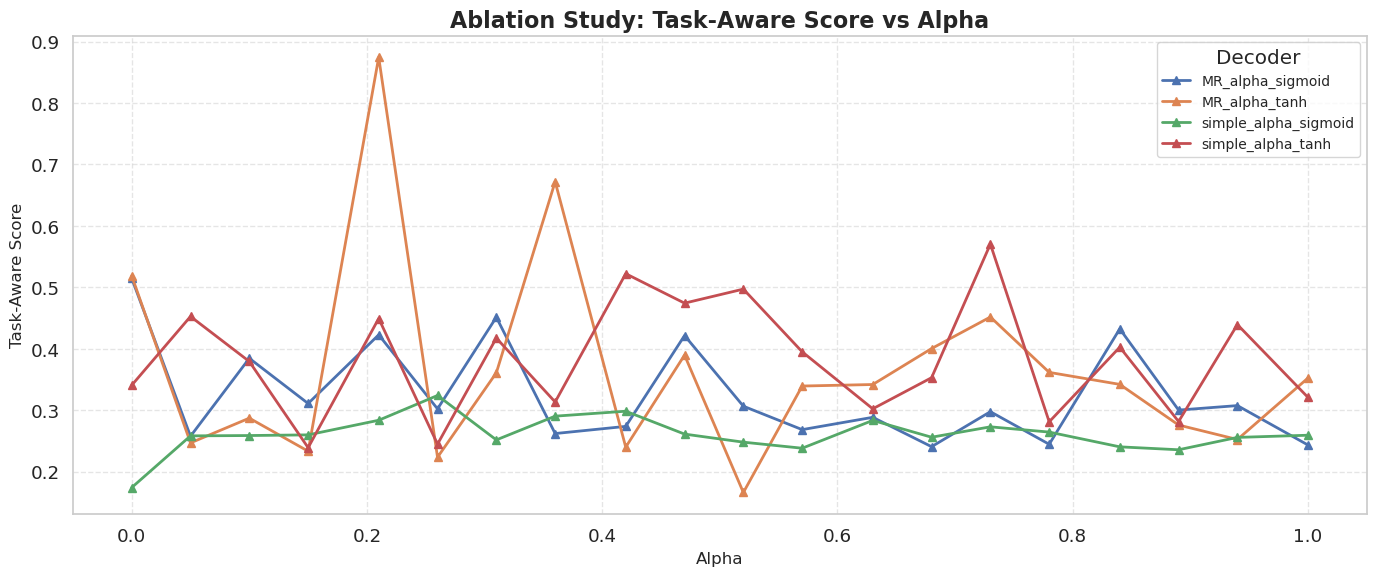

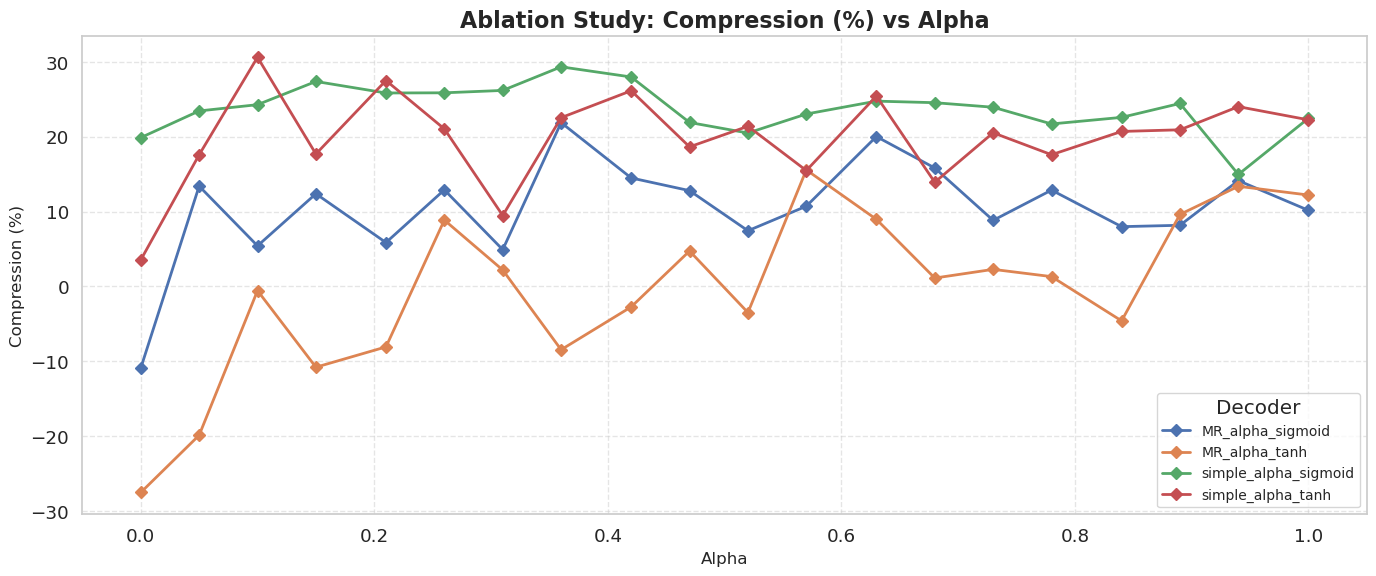

In [16]:
sns.set(style="whitegrid", font_scale=1.2)

# Unique decoders
decoders = df_ablation["decoder_group"].unique()

# Downsample function
def downsample(df, n_points=20):
    if len(df) <= n_points:
        return df
    idx = np.linspace(0, len(df)-1, n_points).astype(int)
    return df.iloc[idx]

# Metrics and plotting properties
metrics = {
    "recon_CE": {"ylabel": "Cross-Entropy (Lower = Better)", "marker": "s"},
    "recon_acc": {"ylabel": "Reconstruction Accuracy", "marker": "o"},
    "TaskAwareScore": {"ylabel": "Task-Aware Score", "marker": "^"},
    "compression_pct": {"ylabel": "Compression (%)", "marker": "D"}
}

# Plot each metric separately with downsampling
for metric, props in metrics.items():
    plt.figure(figsize=(14,6))
    plt.title(f"Ablation Study: {props['ylabel']} vs Alpha", fontsize=16, weight='bold')
    
    for decoder in decoders:
        df_dec = df_ablation[df_ablation["decoder_group"] == decoder].sort_values("alpha").reset_index(drop=True)
        df_plot = downsample(df_dec, n_points=20)
        plt.plot(df_plot["alpha"], df_plot[metric],
                 label=decoder, marker=props["marker"], linewidth=2, markersize=6)
    
    plt.xlabel("Alpha", fontsize=12)
    plt.ylabel(props["ylabel"], fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend(title="Decoder", fontsize=10, loc='best', frameon=True)
    plt.tight_layout()
    plt.show()


Todo: 

- architecture ablation bar chart(simple, mr decoders against ce, accuracy, compression, task-aware score)
- activation ablation bar chart(tanh, sigmoid against ce, accuracy, compression, task-aware score)
- alpha value vs task-aware score for all four architectures side by side
- show a simple visualization of
  - original image | simple tanh image | simple sigmoid image | mr tanh image | mr sigmoid image | size matched lossy compressed image
- relabelling of graphs to make names more intuitive and simple